# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [32]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [33]:
df = pd.read_csv('data/AviationData_cleaned.csv')

# People killed or seriously hurt, and as a fraction of everyone on board
df['Fatal.Serious.Count'] = df['Total.Fatal.Injuries'] + df['Total.Serious.Injuries']
df['Fatal.Serious.Rate'] = df['Fatal.Serious.Count'] / df['Total.Onboard']

print(df.shape)   

(53954, 31)


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [34]:
type_capacity = df.groupby('Make.Model')['Total.Onboard'].quantile(0.75)
df['Size'] = np.where(df['Make.Model'].map(type_capacity) > 20, 'Large', 'Small')

small = df[df['Size'] == 'Small'].copy()
large = df[df['Size'] == 'Large'].copy()

print(df['Size'].value_counts())
print('Mean fatal/serious rate:', small['Fatal.Serious.Rate'].mean().round(3), 'small |', large['Fatal.Serious.Rate'].mean().round(3), 'large')
print('Destroyed rate:', small['Destroyed'].mean().round(3), 'small |', large['Destroyed'].mean().round(3), 'large')

Size
Small    53339
Large      615
Name: count, dtype: int64
Mean fatal/serious rate: 0.276 small | 0.182 large
Destroyed rate: 0.209 small | 0.197 large


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

                                  n  mean_fs_rate  destroyed_rate
Make                                                             
BOMBARDIER                       14         0.093           0.071
GRUMMAN-SCHWEIZER               118         0.103           0.220
WACO                             97         0.132           0.103
GREAT LAKES                      54         0.139           0.111
MCDONNELL DOUGLAS                18         0.139           0.222
MAULE                           488         0.159           0.088
HELIO                            67         0.171           0.164
SCHWEIZER                       140         0.171           0.200
GRUMMAN                         924         0.178           0.228
BOEING                          328         0.189           0.131
WEATHERLY                        75         0.200           0.213
AVIAT                           221         0.201           0.063
WSK PZL MIELEC                   57         0.202           0.228
STINSON   

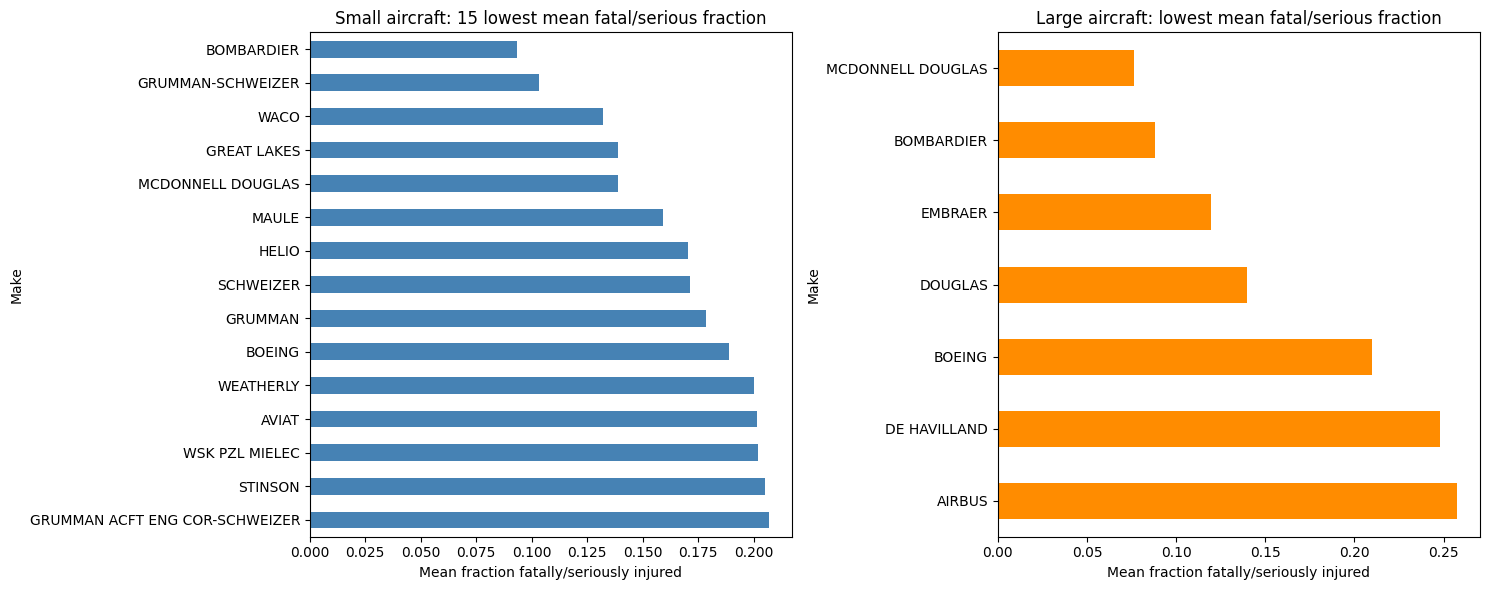

In [35]:
def group_table(data, by, min_n=10):
    t = data.groupby(by).agg(n=('Destroyed', 'size'),
                             mean_fs_rate=('Fatal.Serious.Rate', 'mean'),
                             destroyed_rate=('Destroyed', 'mean'))
    return t[t['n'] >= min_n]

small_makes = group_table(small, 'Make')
large_makes = group_table(large, 'Make')

low_small = small_makes.sort_values('mean_fs_rate').head(15)
low_large = large_makes.sort_values('mean_fs_rate').head(15)
print(low_small.round(3))
print(low_large.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
low_small['mean_fs_rate'].sort_values(ascending=False).plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('Small aircraft: 15 lowest mean fatal/serious fraction')
low_large['mean_fs_rate'].sort_values(ascending=False).plot.barh(ax=axes[1], color='darkorange')
axes[1].set_title('Large aircraft: lowest mean fatal/serious fraction')
for ax in axes:
    ax.set_xlabel('Mean fraction fatally/seriously injured')
plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

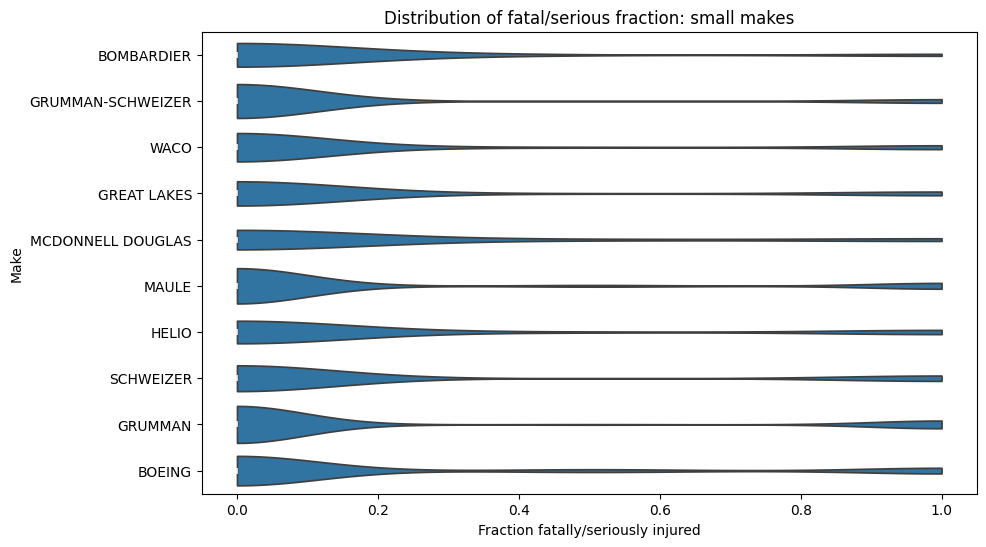

In [36]:
top10_small = small_makes.sort_values('mean_fs_rate').head(10).index

plt.figure(figsize=(10, 6))
sns.violinplot(data=small[small['Make'].isin(top10_small)],
               x='Fatal.Serious.Rate', y='Make', order=top10_small, cut=0)
plt.title('Distribution of fatal/serious fraction: small makes')
plt.xlabel('Fraction fatally/seriously injured')
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

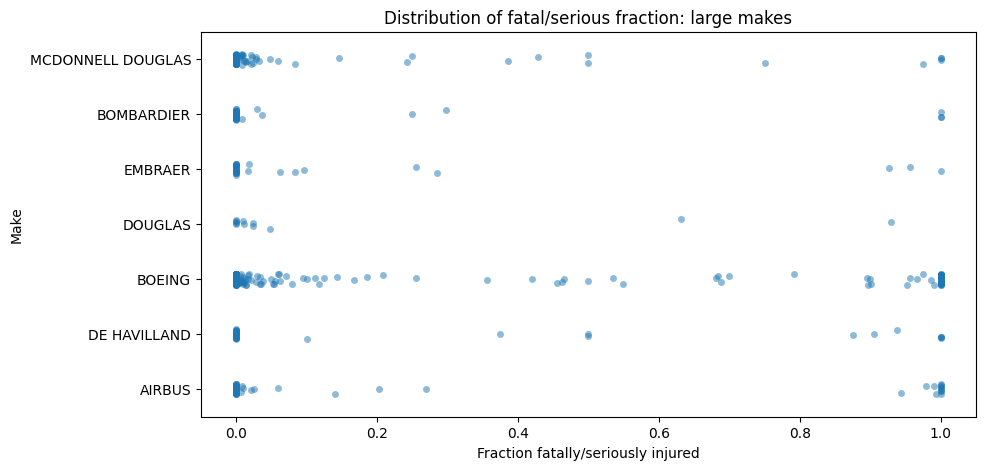

In [37]:
top10_large = large_makes.sort_values('mean_fs_rate').head(10).index   # only 7 qualify

plt.figure(figsize=(10, 5))
sns.stripplot(data=large[large['Make'].isin(top10_large)],
              x='Fatal.Serious.Rate', y='Make', order=top10_large, alpha=0.5)
plt.title('Distribution of fatal/serious fraction: large makes')
plt.xlabel('Fraction fatally/seriously injured')
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [38]:
destroyed_small = small_makes.sort_values('destroyed_rate').head(15)
destroyed_large = large_makes.sort_values('destroyed_rate').head(15)
print(destroyed_small.round(3))
print(destroyed_large.round(3))

                                  n  mean_fs_rate  destroyed_rate
Make                                                             
GRUMMAN ACFT ENG COR-SCHWEIZER   58         0.207           0.017
DIAMOND AIRCRAFT IND             72         0.229           0.056
AVIAT                           221         0.201           0.063
BOMBARDIER                       14         0.093           0.071
MAULE                           488         0.159           0.088
ERCOUPE                          72         0.350           0.097
LUSCOMBE                        362         0.230           0.099
AMERICAN CHAMPION                68         0.294           0.103
WACO                             97         0.132           0.103
GREAT LAKES                      54         0.139           0.111
TAYLORCRAFT                     318         0.300           0.113
GRUMMAN AMERICAN AVN             50         0.347           0.120
ROCKWELL INTERNATIONAL           66         0.239           0.121
BOEING    

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

## Findings for makes

**What the data shows**

In most accidents, nobody on board was seriously hurt. The makes differ mainly in how often an accident turned out very badly, meaning the aircraft was destroyed or everyone on board was badly hurt. The violin and strip plots show this: almost every make has most of its accidents at zero injuries, with a few at the extreme.

**Small aircraft**

Maule, Aviat and Stinson are the best choices. Few people are seriously hurt in their accidents, and their aircraft are less likely to be destroyed. Maule and Aviat had about one accident in ten end with the aircraft destroyed, compared with about one in five for small aircraft overall. Each make also has a large number of accidents behind it, so the result is reliable. Grumman is also good on injuries, but its aircraft are destroyed more often, so it is a weaker choice.

**Large aircraft**

McDonnell Douglas, Bombardier and Embraer are the best choices. They have the lowest injury fractions and are least likely to be destroyed. Boeing has the most data and performs about average. Airbus and De Havilland perform worse than the others.

**Recommendation**

- Small aircraft: Maule, Aviat, Stinson.
- Large aircraft: McDonnell Douglas, Bombardier, Embraer.

**Caution**

Only seven large makes had enough accidents to compare, and most have fewer than 100. Differences between makes that are close together are not conclusive. Makes with very few accidents, such as Bombardier in the small group, were treated with care.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

                         n  mean_fs_rate  destroyed_rate
Make.Model                                              
MCDONNELL DOUGLAS MD88  17         0.003           0.000
MCDONNELL DOUGLAS MD80  10         0.011           0.000
BOMBARDIER CL6002C10    10         0.026           0.000
BOEING 727200           12         0.087           0.083
BOMBARDIER CL6002B19    21         0.098           0.095
BOEING 737300           15         0.109           0.200
BOEING 747              14         0.150           0.143
MCDONNELL DOUGLAS MD11  23         0.152           0.217
BOEING 767              13         0.176           0.231
BOEING 737              65         0.248           0.200
DE HAVILLAND DHC6300    21         0.293           0.333
BOEING 737400           10         0.384           0.500
BOEING 737200           21         0.517           0.571


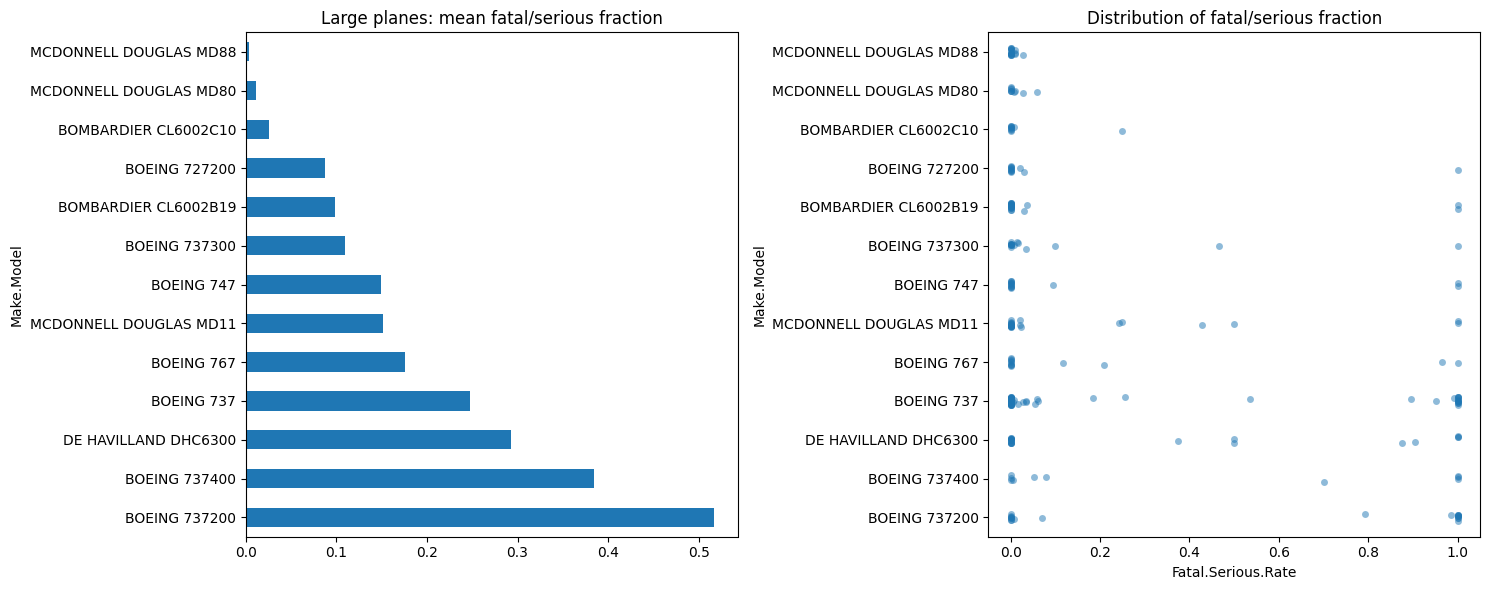

In [39]:
large_types = group_table(large, 'Make.Model').sort_values('mean_fs_rate')
print(large_types.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
large_types['mean_fs_rate'].sort_values(ascending=False).plot.barh(ax=axes[0])
axes[0].set_title('Large planes: mean fatal/serious fraction')
sns.stripplot(data=large[large['Make.Model'].isin(large_types.index)],
              x='Fatal.Serious.Rate', y='Make.Model', order=large_types.index, alpha=0.5, ax=axes[1])
axes[1].set_title('Distribution of fatal/serious fraction')
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

                           n  mean_fs_rate  destroyed_rate
Make.Model                                                
MAULE MX7235              22         0.023           0.000
GRUMMAN-SCHWEIZER G164A   49         0.034           0.163
MAULE M4                  26         0.038           0.038
BOEING E75                33         0.076           0.121
GREAT LAKES 2T1A          11         0.091           0.091
MAULE M4220C              41         0.098           0.098
MAULE MT7235              10         0.100           0.000
MAULE M7235B              14         0.107           0.000
MAULE M7235C              18         0.111           0.056
GRUMMAN G164B            195         0.123           0.251
GRUMMAN G164A            355         0.127           0.225
GREAT LAKES 2T1A2         41         0.134           0.122
MAULE MX7                 24         0.135           0.000
BOEING E75N1              11         0.136           0.091
BOEING A75N1(PT17)        40         0.138           0.0

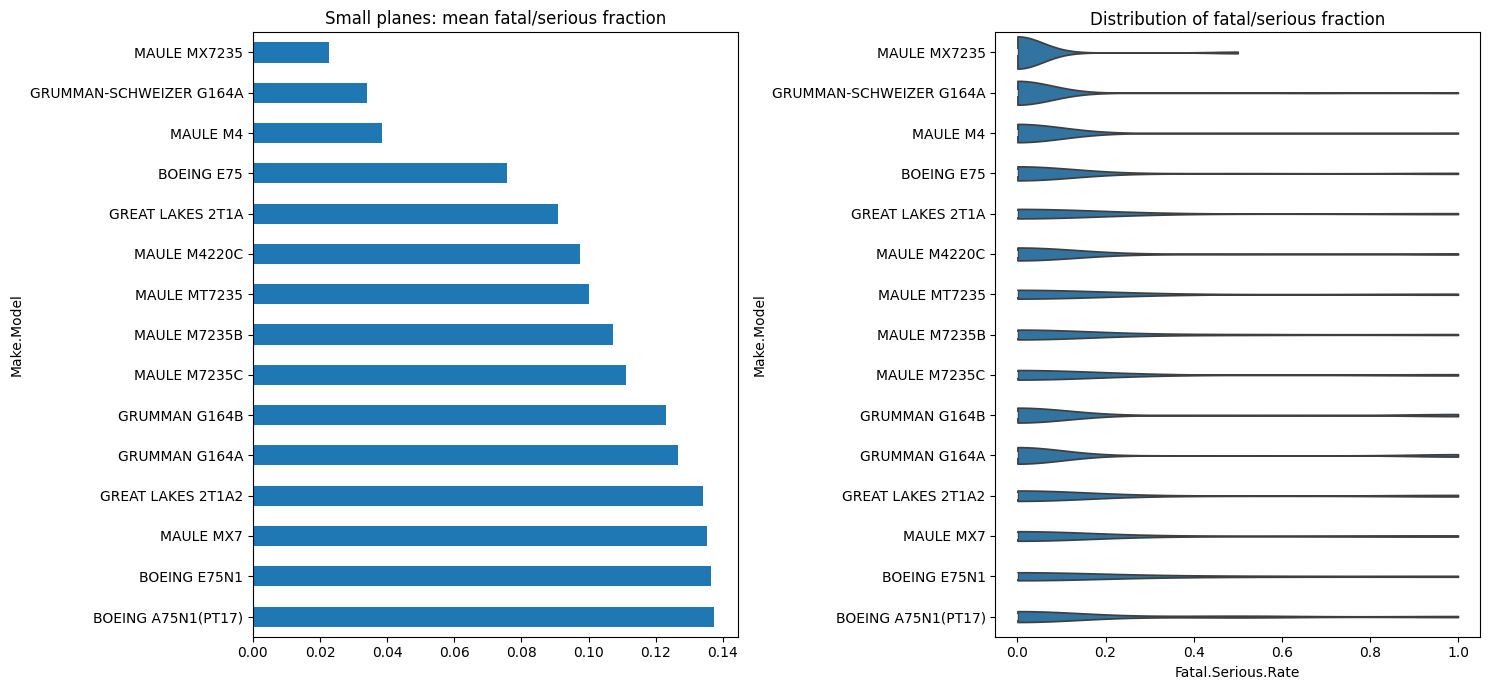

In [40]:
small_top_makes = small[small['Make'].isin(top10_small)]
small_types = group_table(small_top_makes, 'Make.Model').sort_values('mean_fs_rate').head(15)
print(small_types.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
small_types['mean_fs_rate'].sort_values(ascending=False).plot.barh(ax=axes[0])
axes[0].set_title('Small planes: mean fatal/serious fraction')
sns.violinplot(data=small_top_makes[small_top_makes['Make.Model'].isin(small_types.index)],
               x='Fatal.Serious.Rate', y='Make.Model', order=small_types.index, cut=0, ax=axes[1])
axes[1].set_title('Distribution of fatal/serious fraction')
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

## Findings for specific airplane types

**What the data shows**

Looking at individual models shows bigger differences than looking at makes. Within one make, some models are very safe and others are very risky. As with makes, most accidents left nobody seriously hurt, so the models differ in how often an accident turned out very badly.

**Large planes**

The McDonnell Douglas MD-80 and MD-88 and the Bombardier CL-600 variants performed best. Almost nobody on board was seriously hurt in their accidents, and none of their aircraft were destroyed. The Boeing 727-200 also did well. The early Boeing 737 variants (the 737-200 and 737-400) performed worst, with about half of the people on board seriously hurt or killed and about half of the aircraft destroyed. The common Boeing 737 sits in the middle. This shows that "Boeing" as a make hides large differences between its models.

**Small planes**

Maule models have the lowest injury fractions, and in most of them nobody was seriously hurt. The Grumman G164 models are also low on injuries and have the largest samples, which makes their results the most reliable. However, a higher share of the Grumman aircraft were destroyed, so Maule models are the better overall choice.

**Recommendation**

- Large aircraft: the MD-80, MD-88 and Bombardier CL-600 variants. Avoid the early Boeing 737 variants.
- Small aircraft: Maule models.

**Caution**

Each large plane type has only about 10 to 65 accidents, so the ranking is a guide and not proof. A single accident can move the result for a type with only ten. Only types with at least ten accidents were included, and for small planes only the ten best makes were examined.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

                   n  destroyed_rate  mean_fs_rate
Engine.Type                                       
Turbo Fan        832           0.225         0.220
Reciprocating  50533           0.205         0.271
Turbo Jet        126           0.325         0.342
Turbo Prop      2316           0.288         0.365
p-value destroyed: 2.0475731852748765e-22 | p-value injury fraction: 2.641575636374141e-26


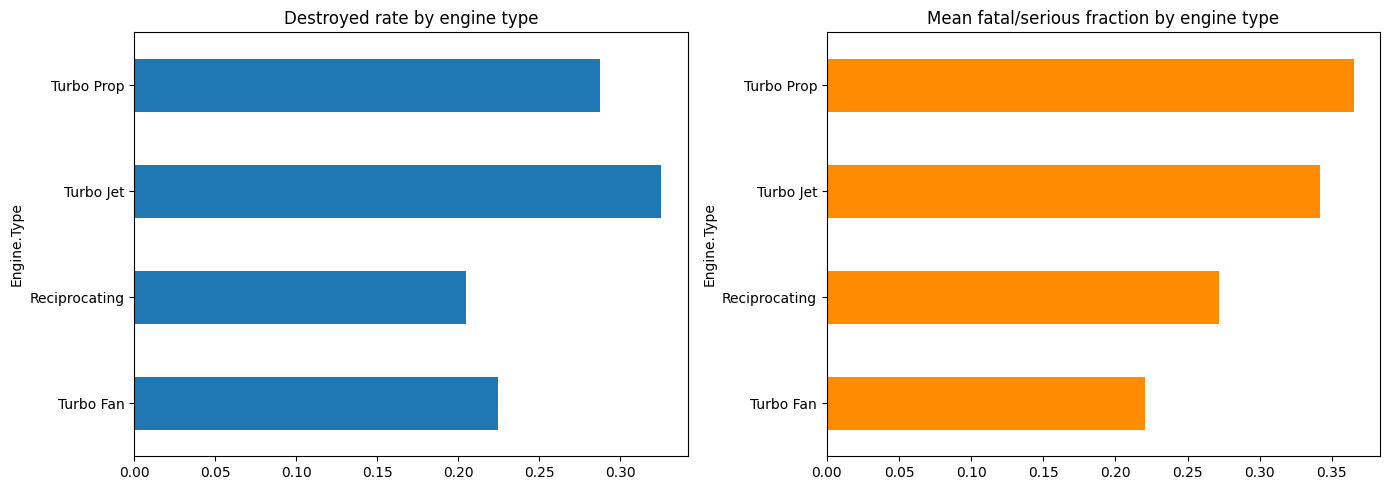

In [41]:
from scipy import stats

# Drop the few missing values, and engine types with fewer than 30 accidents
engine = df.dropna(subset=['Engine.Type'])
engine_counts = engine['Engine.Type'].value_counts()
engine = engine[engine['Engine.Type'].isin(engine_counts[engine_counts >= 30].index)]

engine_summary = engine.groupby('Engine.Type').agg(
    n=('Destroyed', 'size'),
    destroyed_rate=('Destroyed', 'mean'),
    mean_fs_rate=('Fatal.Serious.Rate', 'mean')
).sort_values('mean_fs_rate')
print(engine_summary.round(3))

# Are the differences real?
p_destroyed = stats.chi2_contingency(pd.crosstab(engine['Engine.Type'], engine['Destroyed']))[1]
p_rate = stats.kruskal(*[g['Fatal.Serious.Rate'].values for _, g in engine.groupby('Engine.Type')])[1]
print('p-value destroyed:', p_destroyed, '| p-value injury fraction:', p_rate)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
engine_summary['destroyed_rate'].plot.barh(ax=axes[0])
axes[0].set_title('Destroyed rate by engine type')
engine_summary['mean_fs_rate'].plot.barh(ax=axes[1], color='darkorange')
axes[1].set_title('Mean fatal/serious fraction by engine type')
plt.tight_layout()
plt.show()

**Interpretation: engine type**

Almost all accidents involve piston (reciprocating) engines. About one in five of those aircraft were destroyed. Turbo prop and turbo jet accidents were more severe, with roughly three in ten aircraft destroyed and a higher share of people seriously hurt. Turbo fan aircraft, which are the large jets, had the lowest injury fraction. The differences are statistically significant (p < 0.001). Turbo shaft engines were left out because there were only 12 accidents.

**Caution:** engine type is closely linked to the type of plane. Turbo fan accidents are mostly large aircraft with many people on board, which dilutes the injury fraction, and piston engines are used almost only in small planes. Among small planes alone, turbo fan accidents were more severe than average. So engine type is an association and does not show that the engine causes the difference.

                           n  destroyed_rate  mean_fs_rate
Broad.phase.of.flight                                     
Taxi                    1228           0.020         0.017
Landing                10761           0.042         0.035
Standing                 409           0.127         0.093
Takeoff                 7932           0.216         0.227
Go-around               1084           0.286         0.299
Descent                 1121           0.336         0.352
Approach                4047           0.298         0.353
Cruise                  6420           0.345         0.356
Climb                   1209           0.444         0.444
Maneuvering             4181           0.464         0.525
p-value destroyed: 0.0 | p-value injury fraction: 0.0


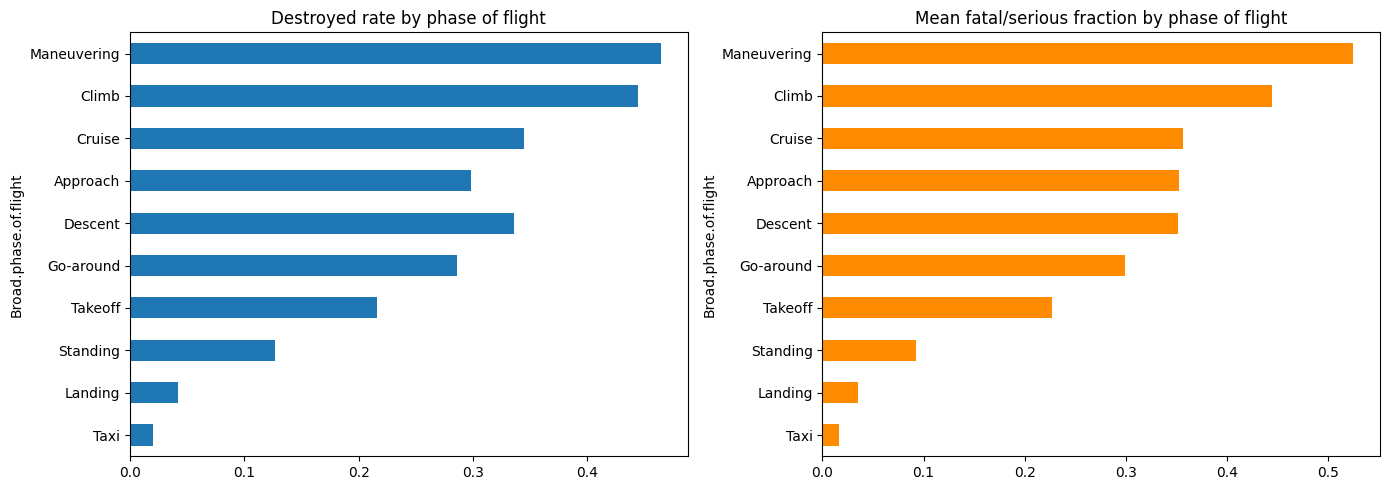

In [42]:
# 'Unknown' and 'Other' carry no information, so they are excluded
phase = df[~df['Broad.phase.of.flight'].isin(['Unknown', 'Other'])].dropna(subset=['Broad.phase.of.flight'])

phase_summary = phase.groupby('Broad.phase.of.flight').agg(
    n=('Destroyed', 'size'),
    destroyed_rate=('Destroyed', 'mean'),
    mean_fs_rate=('Fatal.Serious.Rate', 'mean')
).sort_values('mean_fs_rate')
print(phase_summary.round(3))

p_destroyed = stats.chi2_contingency(pd.crosstab(phase['Broad.phase.of.flight'], phase['Destroyed']))[1]
p_rate = stats.kruskal(*[g['Fatal.Serious.Rate'].values for _, g in phase.groupby('Broad.phase.of.flight')])[1]
print('p-value destroyed:', p_destroyed, '| p-value injury fraction:', p_rate)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
phase_summary['destroyed_rate'].plot.barh(ax=axes[0])
axes[0].set_title('Destroyed rate by phase of flight')
phase_summary['mean_fs_rate'].plot.barh(ax=axes[1], color='darkorange')
axes[1].set_title('Mean fatal/serious fraction by phase of flight')
plt.tight_layout()
plt.show()

**Interpretation: phase of flight**

The further the aircraft is from the ground, the more severe the accident. Taxi and landing accidents are the least severe, and few people are hurt. Takeoff is moderate. Cruise, climb and maneuvering are the most severe, and in maneuvering and climb nearly half of the aircraft were destroyed. The two charts rank the phases in almost the same order, and the differences are statistically significant (p < 0.001).

Landing is the phase with the most accidents, but these are rarely serious. So counting accidents alone would give a misleading picture of risk, and severity matters more for the client.